In [1]:
from gaia_variable_stars import plots
from gaia_variable_stars.modeling.train import fit, load, save

import pandas as pd
from gaia_variable_stars.config import CLEAN_FILE, FEATURES

In [2]:
feat = load()
feat["class_name"].value_counts()

class_name
Cepheid                 500
Long-Period Variable    499
Eclipsing Binary        483
RR Lyrae                472
Name: count, dtype: int64

In [3]:
out = fit(feat)
out["cv"]

,model,f1,std
0,boost,0.964738,0.005790
1,forest,0.955652,0.012170
2,svm,0.936806,0.007868
3,logreg,0.895561,0.024201


In [4]:
print(f"{out['best']}: acc={out['acc']:.3f}  f1={out['f1']:.3f}")
out["report"]

boost: acc=0.972  f1=0.972


,precision,recall,f1-score,support
RR Lyrae,0.948980,0.989362,0.968750,94.000000
Cepheid,0.969697,0.960000,0.964824,100.000000
Eclipsing Binary,0.979167,0.969072,0.974093,97.000000
Long-Period Variable,0.989796,0.970000,0.979798,100.000000
accuracy,0.971867,0.971867,0.971867,0.971867
macro avg,0.971910,0.972108,0.971866,391.000000
weighted avg,0.972206,0.971867,0.971897,391.000000


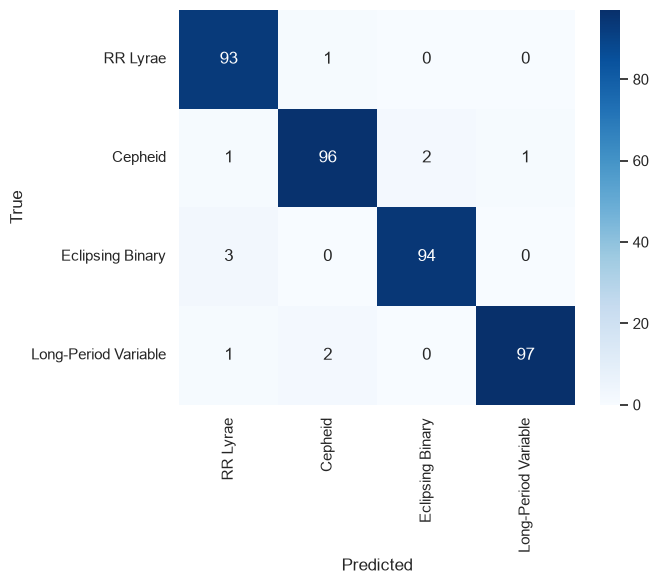

In [5]:
plots.confusion(out["matrix"])

In [6]:
out["rank"]

,feature,drop,std
0,log_period,0.279206,0.014273
1,bp_rp_color,0.243346,0.021040
2,magnitude_skew,0.147377,0.014687
3,power,0.072048,0.009248
4,magnitude_mean,0.026867,0.005598
5,fourier_amp,0.024353,0.006101
6,fourier_ratio,0.013192,0.003058
7,magnitude_std,0.004636,0.002912
8,magnitude_kurt,-0.000537,0.002384
9,amplitude,-0.000658,0.003857


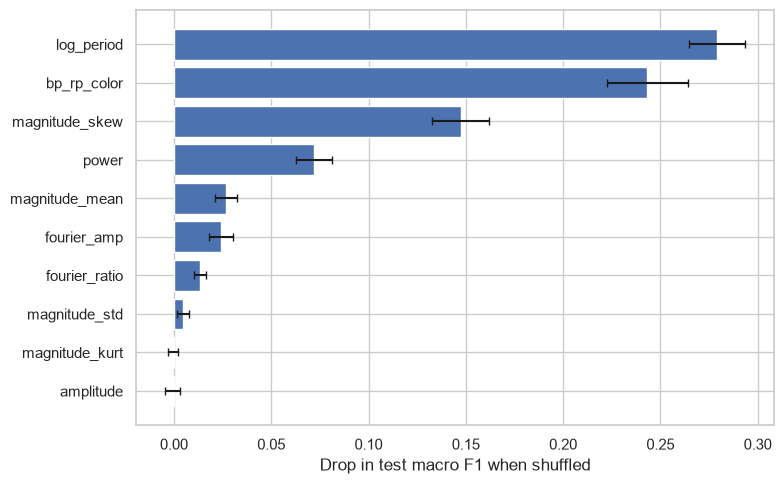

In [7]:
plots.importance(out["rank"])

In [8]:
save(out)

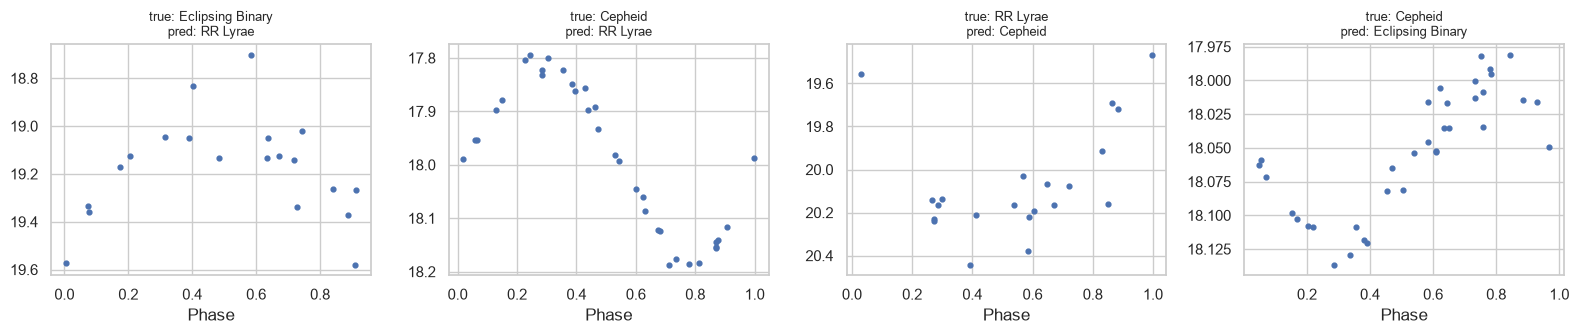

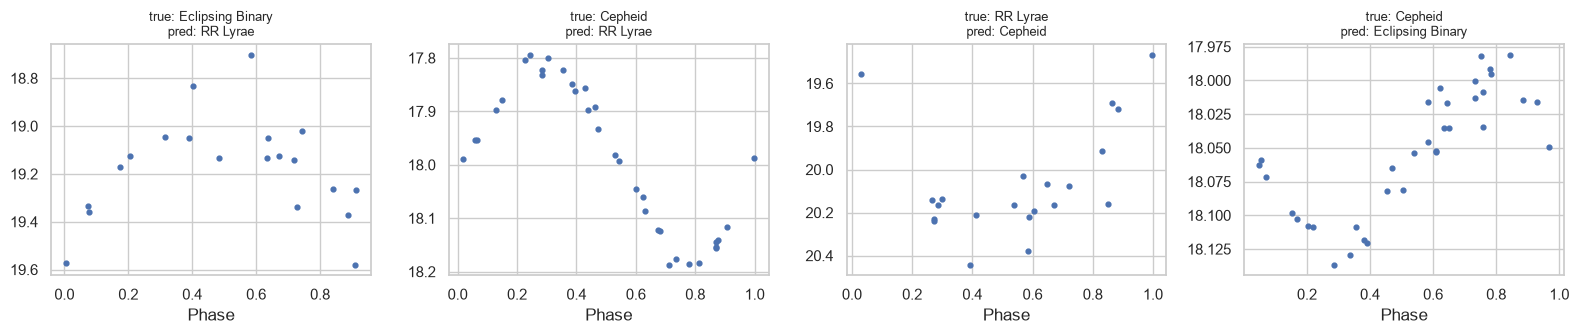

In [9]:
data = pd.read_csv(CLEAN_FILE, low_memory=False)
plots.wrong(data, feat, out["test"])

In [10]:
nocolor = [f for f in FEATURES if f != "bp_rp_color"]
alt = fit(feat, nocolor)
print(f"with color: {out['f1']:.3f}   without: {alt['f1']:.3f}")
alt["rank"]

with color: 0.972   without: 0.944


,feature,drop,std
0,log_period,0.347624,0.014591
1,magnitude_skew,0.181101,0.015778
2,power,0.154782,0.011700
3,fourier_amp,0.085296,0.013353
4,magnitude_mean,0.069173,0.011209
5,fourier_ratio,0.023433,0.004968
6,magnitude_std,0.008305,0.004131
7,amplitude,0.007875,0.004755
8,magnitude_kurt,0.002213,0.004399


In [11]:
import gaia_variable_stars.plots as p
print(p.__file__)

/Users/Sumaitat/Documents/Coding/gaia-dr3-variable-star-classification/gaia_variable_stars/plots.py
